# Métricas e treinamento · XGBoost

GridSearchCV reproduzível, baseline e diagnósticos de **treino e validação**.
**TEST não é avaliado neste notebook.** Os gráficos leem artefatos persistidos;
abrir ou executar o notebook com a configuração padrão não repete a busca.

## 1. Protocolo e origem das métricas

- Alvo `Machine failure`, positivo `1`. Entradas: cinco sensores e `Type`.
- Mesma reserva da EDA: 8.000 registros de desenvolvimento e 2.000 em TEST reservado.
- Dentro dos 8.000: prefixo **FIT de 6.400** para GridSearchCV, seguido de **1.600 em VALIDAÇÃO**.
- Três folds com prefixos crescentes dentro de FIT, sem shuffle ou gap. UDI é ordem,
  não data real; não se demonstra independência temporal nem entre máquinas.
- **Critério:** maior média de AP na CV; empate exato usa primeiro candidato da grade.
  AP é Average Precision, não integração trapezoidal da PR. O vencedor é o melhor
  da grade pesquisada, sem garantia de ótimo global.
- **Refit:** melhores parâmetros reajustados apenas nas 6.400 observações FIT.
  A validação de 1.600 não participa do ajuste nem do GridSearchCV.
- **Decisão:** `score >= 0.5`, referência fixa e não limiar operacional ótimo.
- Imputação e one-hot dentro do pipeline/folds; árvores sem scaling. Sem SMOTE,
  undersampling, seleção automática de features, calibração ajustada ou early stopping.
- TRAIN completo já participou da EDA: a validação é interna ao desenvolvimento,
  não uma confirmação independente. Os scores do vencedor na CV têm otimismo de seleção.

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'configs/training.json').is_file() and (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from predictive_maintenance.training import run_experiment, latest_run
from predictive_maintenance.reporting import ModelReport
from predictive_maintenance.presentation import readable_table, readable_parameters, translate_text

def translated_markdown(text):
    return Markdown(translate_text(text))

from predictive_maintenance.data import sha256

MODEL_NAME = 'xgboost'
RUN_TRAINING = False  # True executa uma nova busca e preserva as anteriores.
RUN_ID = None  # Informe um ID salvo para revisar exatamente aquela execução.
if RUN_TRAINING:
    run = run_experiment(ROOT, MODEL_NAME)
elif RUN_ID:
    run = ROOT / 'reports/experiments' / RUN_ID
else:
    run = latest_run(ROOT, MODEL_NAME)
report = ModelReport(ROOT, run)
manifest = report.manifest
if manifest['model'] != MODEL_NAME:
    raise ValueError('Execução pertence a outro modelo.')
print('Execução:', manifest['run_id'])
print('Dataset SHA256:', manifest['dataset_sha256'])
print('CSV atual corresponde:', sha256(ROOT / manifest['data_config']['source']) == manifest['dataset_sha256'])
print('TEST avaliado:', manifest['test_evaluated'])
display(manifest['versions'])

Execução: train_xgboost_20261031T004336Z_06512d36
Dataset SHA256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e
CSV atual corresponde: True
TEST avaliado: False


{'scikit-learn': '1.9.1',
 'xgboost': '3.4.1',
 'pandas': '2.3.3',
 'numpy': '2.5.4',
 'scipy': '1.18.1',
 'joblib': '1.6.0'}

## 2. Grade, custo e melhores parâmetros

Cada modelo pesquisa 32 candidatos × 3 folds = 96 ajustes de busca, mais um refit.
Há ainda 4 ajustes do baseline e 3 diagnósticos de tamanho com parâmetros congelados.
A busca usa 2 workers e cada estimador usa 1 thread para limitar concorrência.

**Nomenclatura sklearn:** `mean_test_*` e `split*_test_*` nas tabelas da busca
significam validação dos folds dentro de FIT, nunca o conjunto TEST reservado.

A grade investiga número de árvores × learning rate, profundidade,
`min_child_weight` e peso positivo. `scale_pos_weight=10` é uma hipótese fixa
moderada frente a 1, não uma razão calculada sobre validação/TEST.
`subsample=0.8`, `colsample_bytree=0.9`, L1=0 e L2=1 são **fixos**, não otimizados.
Não há early stopping; o número de árvores participa da busca conjunta.

Parâmetro,Descrição,Valor
model__n_estimators,Número de árvores,"[150, 300]"
model__max_depth,Profundidade máxima,"[2, 4]"
model__learning_rate,Taxa de aprendizado,"[0.05, 0.15]"
model__min_child_weight,Peso mínimo de filho,"[1, 5]"
model__scale_pos_weight,Peso da classe positiva,"[1, 10]"


**Parâmetros fixos:**

Parâmetro,Descrição,Valor
objective,Objetivo,binary:logistic
eval_metric,Métrica interna,logloss
tree_method,Método de construção,hist
subsample,Fração de linhas por árvore,0.8
colsample_bytree,Fração de variáveis por árvore,0.9
reg_alpha,Regularização L1,0
reg_lambda,Regularização L2,1
n_jobs,Threads do estimador,1


**Melhores parâmetros na grade:**

Parâmetro,Descrição,Valor
model__learning_rate,Taxa de aprendizado,0.05
model__max_depth,Profundidade máxima,4
model__min_child_weight,Peso mínimo de filho,1
model__n_estimators,Número de árvores,150
model__scale_pos_weight,Peso da classe positiva,10


AP média de seleção: 0.4955
Tempo da busca: 35.2 s


,AP (score) — posição — validação CV,AP (score) — média — validação CV,AP (score) — desvio — validação CV,AP (score) — média — treino CV,F1 (%) — média — validação CV,Recall (%) — média — validação CV,Precision (%) — média — validação CV,Tempo médio de ajuste (s),Parâmetros
9,1,"0,4955","0,0721","0,9867","38,03%","52,56%","45,13%","0,3194","{""model__learning_rate"": 0.05, ""model__max_depth"": 4, ""model__min_child_weight"": 1, ""model__n_estimators"": 150, ""model__scale_pos_weight"": 10}"
0,2,"0,4938","0,0759","0,8848","33,93%","33,69%","63,47%","0,4372","{""model__learning_rate"": 0.05, ""model__max_depth"": 2, ""model__min_child_weight"": 1, ""model__n_estimators"": 150, ""model__scale_pos_weight"": 1}"
5,3,"0,4893","0,0595","0,8461","35,08%","60,14%","38,85%","0,3334","{""model__learning_rate"": 0.05, ""model__max_depth"": 2, ""model__min_child_weight"": 5, ""model__n_estimators"": 150, ""model__scale_pos_weight"": 10}"
1,4,"0,4805","0,0600","0,8541","35,69%","60,78%","37,36%","0,3572","{""model__learning_rate"": 0.05, ""model__max_depth"": 2, ""model__min_child_weight"": 1, ""model__n_estimators"": 150, ""model__scale_pos_weight"": 10}"
7,5,"0,4739","0,0524","0,9134","36,66%","60,15%","39,60%","0,6027","{""model__learning_rate"": 0.05, ""model__max_depth"": 2, ""model__min_child_weight"": 5, ""model__n_estimators"": 300, ""model__scale_pos_weight"": 10}"
11,6,"0,4734","0,0757","0,9988","39,00%","50,58%","49,10%","0,7278","{""model__learning_rate"": 0.05, ""model__max_depth"": 4, ""model__min_child_weight"": 1, ""model__n_estimators"": 300, ""model__scale_pos_weight"": 10}"
17,7,"0,4644","0,0387","0,9468","38,44%","58,01%","40,25%","0,3880","{""model__learning_rate"": 0.15, ""model__max_depth"": 2, ""model__min_child_weight"": 1, ""model__n_estimators"": 150, ""model__scale_pos_weight"": 10}"
2,8,"0,4640","0,0608","0,9284","40,38%","44,48%","58,80%","0,6499","{""model__learning_rate"": 0.05, ""model__max_depth"": 2, ""model__min_child_weight"": 1, ""model__n_estimators"": 300, ""model__scale_pos_weight"": 1}"
13,9,"0,4602","0,0682","0,9770","39,64%","58,11%","43,56%","0,4457","{""model__learning_rate"": 0.05, ""model__max_depth"": 4, ""model__min_child_weight"": 5, ""model__n_estimators"": 150, ""model__scale_pos_weight"": 10}"
19,10,"0,4575","0,0573","0,9830","39,73%","52,78%","45,47%","0,6086","{""model__learning_rate"": 0.15, ""model__max_depth"": 2, ""model__min_child_weight"": 1, ""model__n_estimators"": 300, ""model__scale_pos_weight"": 10}"


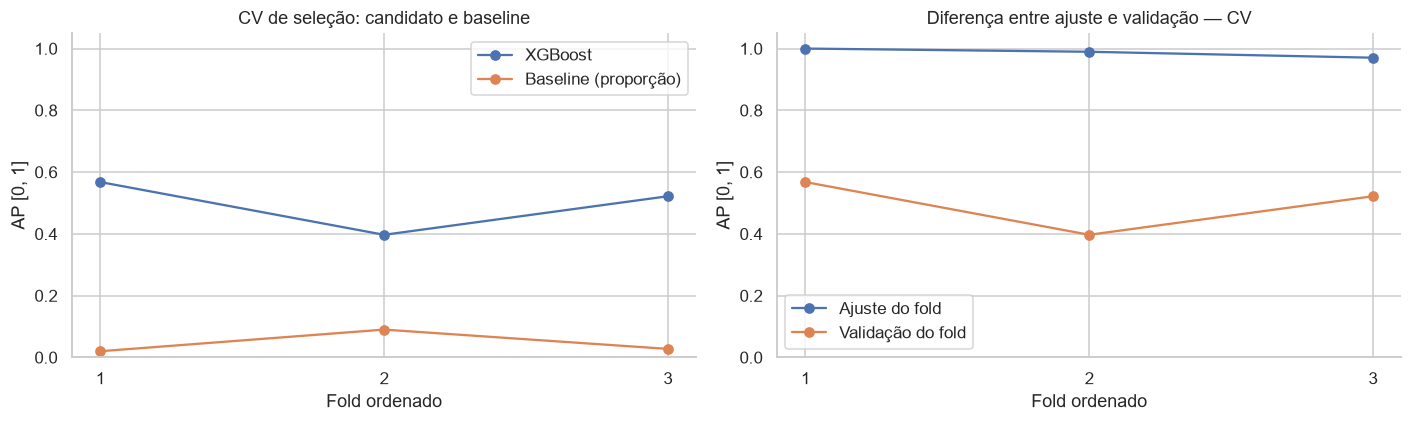

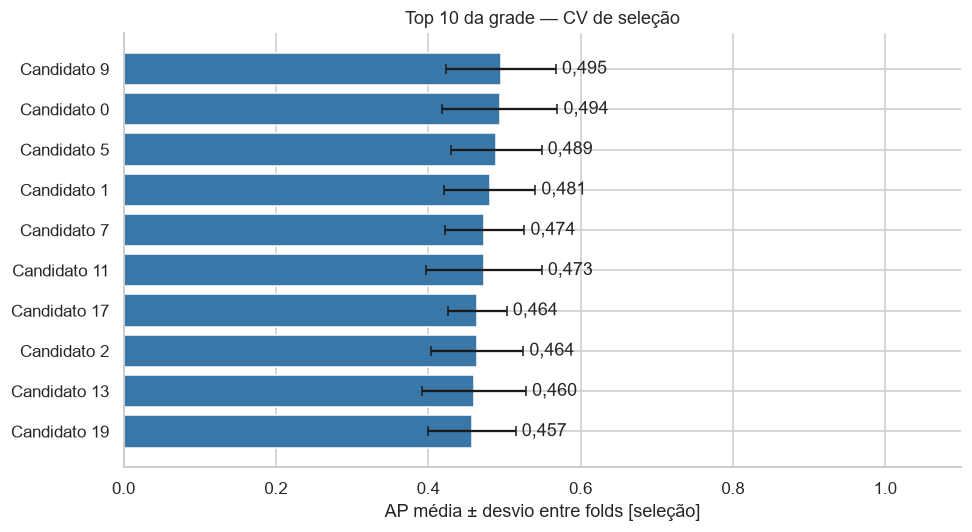

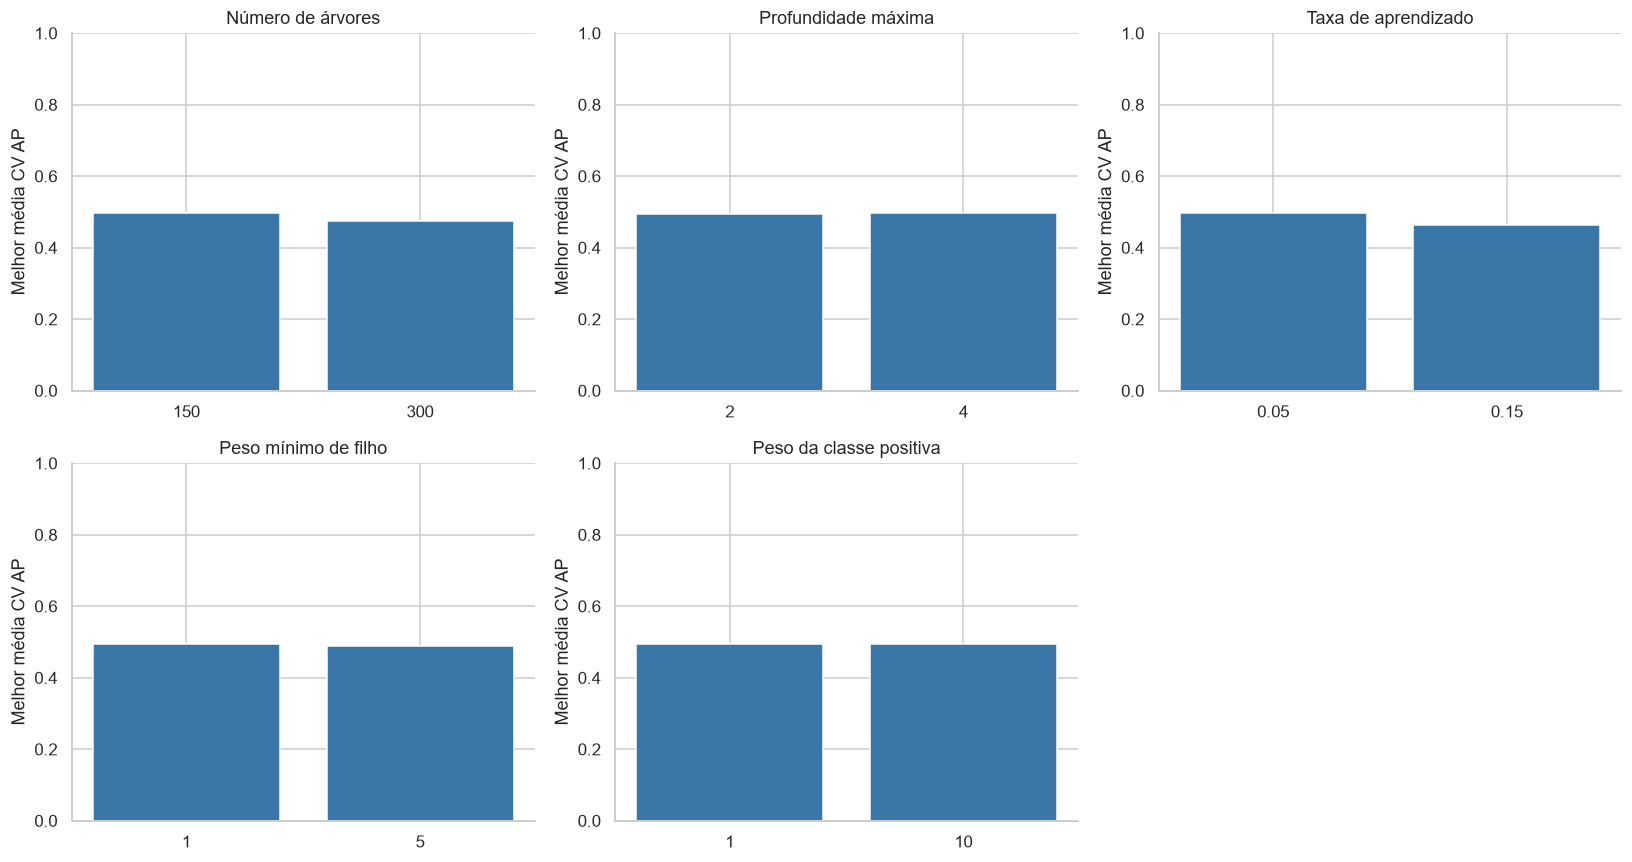

In [2]:
display(readable_parameters(manifest['training_config'][MODEL_NAME]['grid']))
display(translated_markdown('**Parâmetros fixos:**'))
display(readable_parameters(manifest['fixed_params']))
display(translated_markdown('**Melhores parâmetros na grade:**'))
display(readable_parameters(manifest['best_params']))
print(f"AP média de seleção: {manifest['best_cv_ap']:.4f}")
print(f"Tempo da busca: {manifest['search_seconds']:.1f} s")
grid = report.table('grid_results')
columns = ['rank_test_ap', 'mean_test_ap', 'std_test_ap', 'mean_train_ap',
           'mean_test_f1', 'mean_test_recall', 'mean_test_precision', 'mean_fit_time', 'params']
display(readable_table(grid.sort_values('rank_test_ap')[columns].head(10)))
report.cv_figures()

**Leitura dos perfis:** cada barra mostra o melhor AP médio entre combinações
daquele valor, mantendo os demais parâmetros livres na grade. Não é efeito
isolado de hiperparâmetro. Os desvios do top 10 são dispersão entre folds,
não intervalos de confiança ou evidência de superioridade estatística.

## 3. Estatísticas por fold e baseline

`CV_SELECTION` refere-se ao candidato escolhido nas mesmas amostras usadas na
seleção, sem CV aninhada. Não são predições OOF nem resultado de teste.
O baseline Dummy usa a proporção observada no treino de cada fold.
Precision sem alertas é 0 no scorer da CV; nos diagnósticos de segmentos é indefinida (NaN).

In [3]:
folds = report.table('fold_metrics')
display(readable_table(folds))
display(readable_table(report.summary()))
selected_folds = folds.loc[folds.model.eq(MODEL_NAME)]
display(translated_markdown(f"**AP de seleção:** {selected_folds.validation_ap.mean():.3f} ± "
                f"{selected_folds.validation_ap.std(ddof=1):.3f} (desvio amostral entre folds). "
                'Deslocamentos entre blocos e baixo suporte positivo limitam a interpretação.'))

,Receita,Fold ordenado,Origem,Observações de treino,Observações de validação,Falhas no treino,Falhas na validação,Limiar de alerta,AP (score) — treino,AP (score) — validação,ROC-AUC (score) — treino,ROC-AUC (score) — validação,F1 (%) — treino,F1 (%) — validação,Recall (%) — treino,Recall (%) — validação,Precision (%) — treino,Precision (%) — validação,Acurácia balanceada (%) — treino,Acurácia balanceada (%) — validação
0,XGBoost,1,CV de seleção,1.600,1.600,45,32,"0,5000",1,"0,5677",1,"0,9145","97,83%","48,72%","100,00%","59,38%","95,74%","41,30%","99,94%","78,83%"
1,Baseline (proporção),1,CV do baseline,1.600,1.600,45,32,"0,5000","0,0281","0,0200","0,5000","0,5000","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%"
2,XGBoost,2,CV de seleção,3.200,1.600,77,144,"0,5000","0,9896","0,3970","0,9998","0,7979","93,33%","29,67%","100,00%","18,75%","87,50%","71,05%","99,82%","59,00%"
3,Baseline (proporção),2,CV do baseline,3.200,1.600,77,144,"0,5000","0,0241","0,0900","0,5000","0,5000","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%"
4,XGBoost,3,CV de seleção,4.800,1.600,221,44,"0,5000","0,9704","0,5218","0,9984","0,9500","83,62%","35,71%","98,19%","79,55%","72,82%","23,03%","98,21%","86,01%"
5,Baseline (proporção),3,CV do baseline,4.800,1.600,221,44,"0,5000","0,0460","0,0275","0,5000","0,5000","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%"


**AP de seleção:** 0,495 ± 0,088 (desvio amostral entre folds). Deslocamentos entre blocos e baixo suporte positivo limitam a interpretação.

## 4. FIT reajustado versus VALIDAÇÃO

`FIT_RESUBSTITUTION` é desempenho sobre o próprio ajuste, sujeito a sobreajuste.
`VALIDATION_TRAIN_BLOCK` é o bloco posterior fora da busca. Mesmos dados e limiar
para o candidato e o baseline. Nas tabelas e barras, F1/Recall/Precision e taxas aparecem em %, com vírgula decimal; AP e ROC-AUC permanecem scores em 0–1. Desvios de percentuais são pontos percentuais (p.p.). Os artefatos numéricos não são alterados.
`Não definido` nas barras indica ausência de alertas; a altura 0 é apenas convenção visual.

,Receita,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,XGBoost,Treino (reavaliação no ajuste),6.400,265,"4,14%","0,5000",6.023,112,7,258,"81,26%","97,36%","69,73%","98,17%","99,88%","1,83%","2,64%","5,78%","98,14%","97,77%","0,9475","0,9973","0,0167","0,0662","0,8155","0,8031"
1,XGBoost,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.543,22,8,27,"64,29%","77,14%","55,10%","98,59%","99,48%","1,41%","22,86%","3,06%","98,12%","87,87%","0,6796","0,9671","0,0164","0,0628","0,6430","0,6335"
2,Baseline (proporção),Treino (reavaliação no ajuste),6.400,265,"4,14%","0,5000",6.135,0,265,0,"0,00%","0,00%",Não definido,"100,00%","95,86%","0,00%","100,00%","0,00%","95,86%","50,00%","0,0414","0,5000","0,0397","0,1724",0,0
3,Baseline (proporção),Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.565,0,35,0,"0,00%","0,00%",Não definido,"100,00%","97,81%","0,00%","100,00%","0,00%","97,81%","50,00%","0,0219","0,5000","0,0218","0,1110",0,0


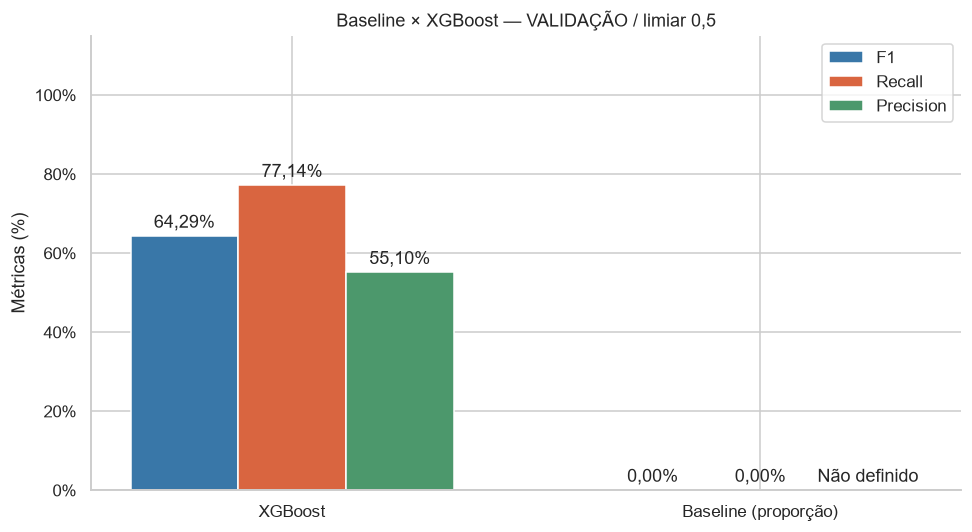

**Validação:** AP=0,680; F1=64,29%; Recall=77,14%; Precision=55,10%. Diferença de AP entre ajuste e validação = 0,268. São 35 falhas em 1600 observações. A diferença pode refletir sobreajuste e mudança entre blocos; não prova causalidade.

In [4]:
metrics = report.table('model_metrics')
display(readable_table(metrics))
report.comparison()
validation = metrics.loc[metrics.model.eq(MODEL_NAME) & metrics.origin.eq('VALIDATION_TRAIN_BLOCK')].iloc[0]
fit = metrics.loc[metrics.model.eq(MODEL_NAME) & metrics.origin.eq('FIT_RESUBSTITUTION')].iloc[0]
display(translated_markdown(f"**Validação:** AP={validation.ap:.3f}; F1={validation.f1:.2%}; "
    f"Recall={validation.recall:.2%}; Precision={validation.precision:.2%}. "
    f"Diferença de AP entre ajuste e validação = {fit.ap - validation.ap:.3f}. "
    f"São {int(validation.positives)} falhas em {int(validation.n)} observações. "
    'A diferença pode refletir sobreajuste e mudança entre blocos; não prova causalidade.'))

## 5. Matriz de confusão e relatório por classe

Eixo vertical real, horizontal previsto; classe positiva = falha. Matrizes em
contagens e normalizadas pela classe real. `zero_division=0` no relatório por classe.

,Classe / média,Precision (%),Recall (%),F1 (%),Observações da classe
0,Sem falha (0),"99,48%","98,59%","99,04%",1.565
1,Falha (1),"55,10%","77,14%","64,29%",35
2,Acurácia,"98,12%","98,12%","98,12%","0,9812"
3,Média macro,"77,29%","87,87%","81,66%",1.600
4,Média ponderada,"98,51%","98,12%","98,28%",1.600


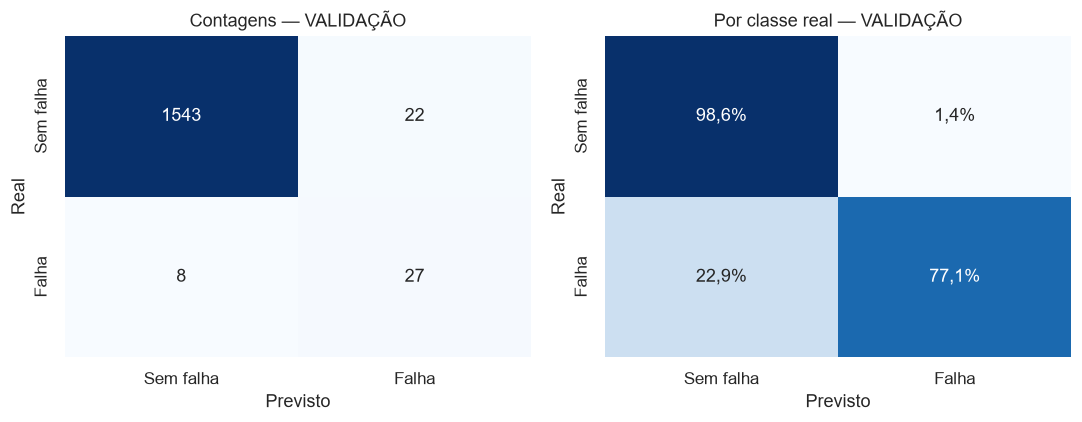

**Carga de revisão no bloco:** 49 alertas; 22 falsos positivos e 8 falhas perdidas. Custos e capacidade operacional ainda não foram informados.

In [5]:
display(readable_table(report.table('classification_report')))
report.confusion()
display(translated_markdown(f"**Carga de revisão no bloco:** {int(validation.tp + validation.fp)} alertas; "
                f"{int(validation.fp)} falsos positivos e {int(validation.fn)} falhas perdidas. "
                'Custos e capacidade operacional ainda não foram informados.'))

## 6. PR, ROC, confiabilidade e distribuição dos scores

AP e ROC usam scores positivos. A prevalência é a referência da PR. ROC complementa
a análise de classe rara. A curva de confiabilidade usa até 10 grupos por quantis;
não ajusta calibrador e não comprova calibração. Pesos de classe podem alterar os scores.

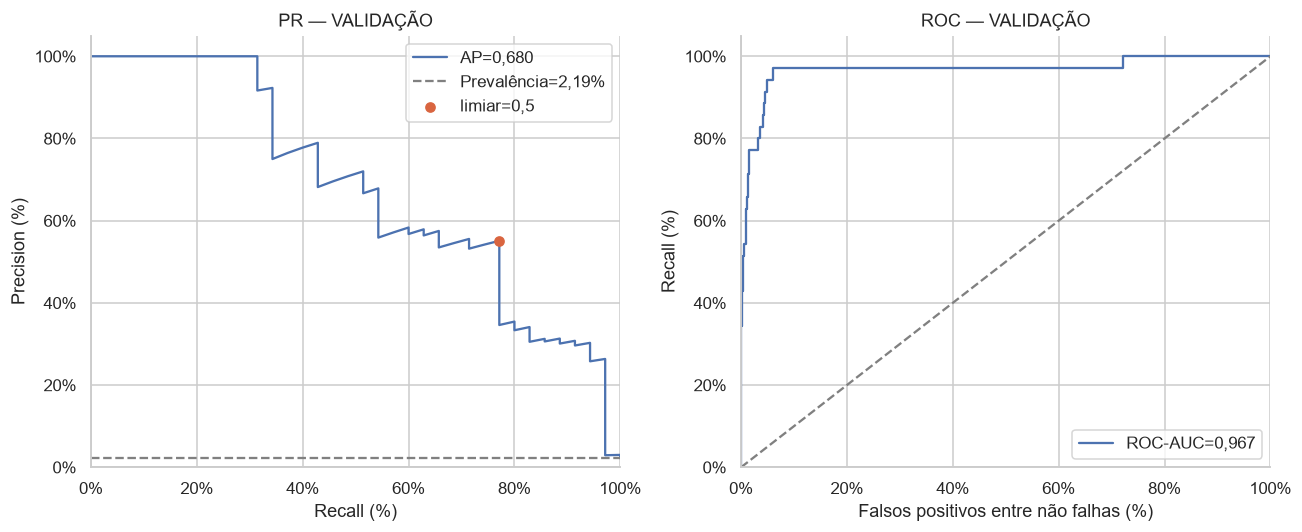

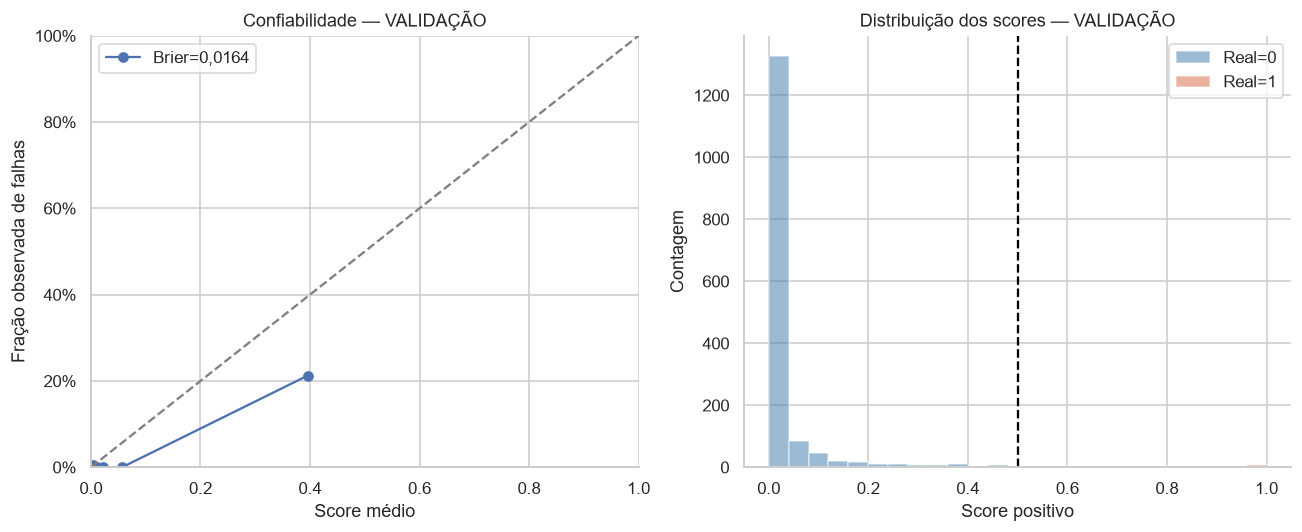

,Score médio,Taxa observada de falhas (%)
0,"0,0016","0,00%"
1,"0,0023","0,00%"
2,"0,0035","0,62%"
3,"0,0046","0,00%"
4,"0,0056","0,00%"
5,"0,0075","0,00%"
6,"0,0114","0,00%"
7,"0,0217","0,00%"
8,"0,0568","0,00%"
9,"0,3960","21,25%"


**Diagnóstico probabilístico:** Brier=0,0164; Log Loss=0,0628. Amostra com poucas falhas limita a estabilidade da curva de confiabilidade.

In [6]:
report.probability_figures()
display(readable_table(report.table('calibration')))
display(translated_markdown(f"**Diagnóstico probabilístico:** Brier={validation.brier:.4f}; "
                f"Log Loss={validation.log_loss:.4f}. "
                'Amostra com poucas falhas limita a estabilidade da curva de confiabilidade.'))

## 7. Sensibilidade ao threshold — sem tuning

O destaque mostra a referência 0,5. Varrer limiares na validação é **diagnóstico**,
sem mudar o pacote ou declarar um ótimo. Recall/Precision/F1 mudam; AP dos mesmos
scores não muda. Uma escolha operacional futura exige objetivo e validação própria.

,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Validação (somente diagnóstico),1.600,35,"2,19%","0,0500",1.356,209,1,34,"24,46%","97,14%","13,99%","86,65%","99,93%","13,35%","2,86%","15,19%","86,88%","91,89%","0,6796","0,9671","0,0164","0,0628","0,3415","0,2146"
1,Validação (somente diagnóstico),1.600,35,"2,19%","0,1000",1.435,130,1,34,"34,17%","97,14%","20,73%","91,69%","99,93%","8,31%","2,86%","10,25%","91,81%","94,42%","0,6796","0,9671","0,0164","0,0628","0,4284","0,3171"
2,Validação (somente diagnóstico),1.600,35,"2,19%","0,2000",1.493,72,4,31,"44,93%","88,57%","30,10%","95,40%","99,73%","4,60%","11,43%","6,44%","95,25%","91,99%","0,6796","0,9671","0,0164","0,0628","0,5005","0,4307"
3,Validação (somente diagnóstico),1.600,35,"2,19%","0,3000",1.515,50,8,27,"48,21%","77,14%","35,06%","96,81%","99,47%","3,19%","22,86%","4,81%","96,38%","86,97%","0,6796","0,9671","0,0164","0,0628","0,5054","0,4661"
4,Validação (somente diagnóstico),1.600,35,"2,19%","0,4000",1.533,32,8,27,"57,45%","77,14%","45,76%","97,96%","99,48%","2,04%","22,86%","3,69%","97,50%","87,55%","0,6796","0,9671","0,0164","0,0628","0,5829","0,5625"
5,Validação (somente diagnóstico),1.600,35,"2,19%","0,5000",1.543,22,8,27,"64,29%","77,14%","55,10%","98,59%","99,48%","1,41%","22,86%","3,06%","98,12%","87,87%","0,6796","0,9671","0,0164","0,0628","0,6430","0,6335"
6,Validação (somente diagnóstico),1.600,35,"2,19%","0,6000",1.548,17,13,22,"59,46%","62,86%","56,41%","98,91%","99,17%","1,09%","37,14%","2,44%","98,12%","80,89%","0,6796","0,9671","0,0164","0,0628","0,5859","0,5850"
7,Validação (somente diagnóstico),1.600,35,"2,19%","0,7000",1.551,14,16,19,"55,88%","54,29%","57,58%","99,11%","98,98%","0,89%","45,71%","2,06%","98,12%","76,70%","0,6796","0,9671","0,0164","0,0628","0,5495","0,5493"
8,Validação (somente diagnóstico),1.600,35,"2,19%","0,8000",1.560,5,20,15,"54,55%","42,86%","75,00%","99,68%","98,73%","0,32%","57,14%","1,25%","98,44%","71,27%","0,6796","0,9671","0,0164","0,0628","0,5600","0,5381"
9,Validação (somente diagnóstico),1.600,35,"2,19%","0,9000",1.563,2,23,12,"48,98%","34,29%","85,71%","99,87%","98,55%","0,13%","65,71%","0,88%","98,44%","67,08%","0,6796","0,9671","0,0164","0,0628","0,5365","0,4833"


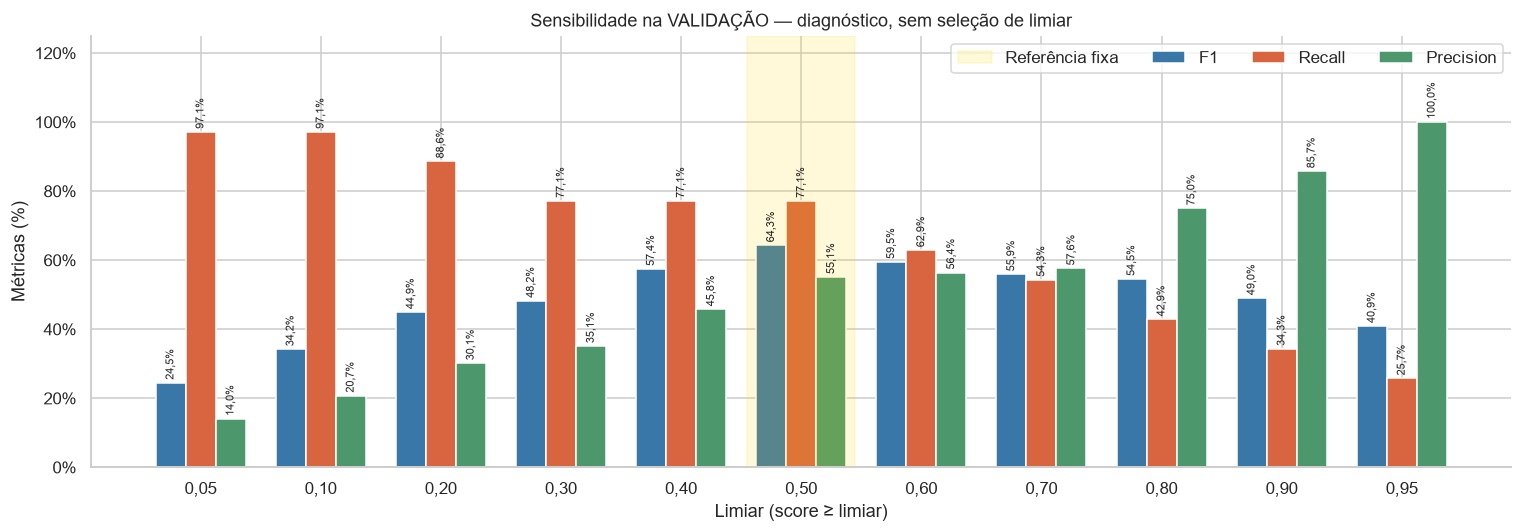

In [7]:
display(readable_table(report.table('threshold_diagnostics')))
report.threshold_figure()

## 8. Associação versus importância preditiva

Associação calculada em FIT: Spearman para sensores, Cramér V para Type (magnitude
com medidas distintas, não equivalentes). Importância por permutação no bloco de
validação, agregada por entrada original passando pelo pipeline completo.
A unidade é queda de AP; as barras de erro são desvio das permutações, não confiança.
Correlação entre sensores pode repartir importâncias. Nada foi removido com esse diagnóstico.

,Variável,Pearson com falha — treino,Spearman com falha — treino,Magnitude da associação — treino,Medida de associação,Queda de AP por permutação — validação,Desvio da permutação (score)
0,Temperatura do ar [K],"0,0861","0,0897","0,0897",Módulo de Spearman,"0,0204","0,0105"
1,Temperatura do processo [K],"0,0439","0,0500","0,0500",Módulo de Spearman,"-0,0314","0,0126"
2,Velocidade de rotação [rpm],"-0,0580","-0,1982","0,1982",Módulo de Spearman,"0,2165","0,0178"
3,Torque [Nm],"0,2110","0,1950","0,1950",Módulo de Spearman,"0,5794","0,0163"
4,Desgaste da ferramenta [min],"0,0925","0,0885","0,0885",Módulo de Spearman,"0,3171","0,0490"
5,Tipo,Não definido,Não definido,"0,0318",V de Cramér,"0,0260","0,0165"


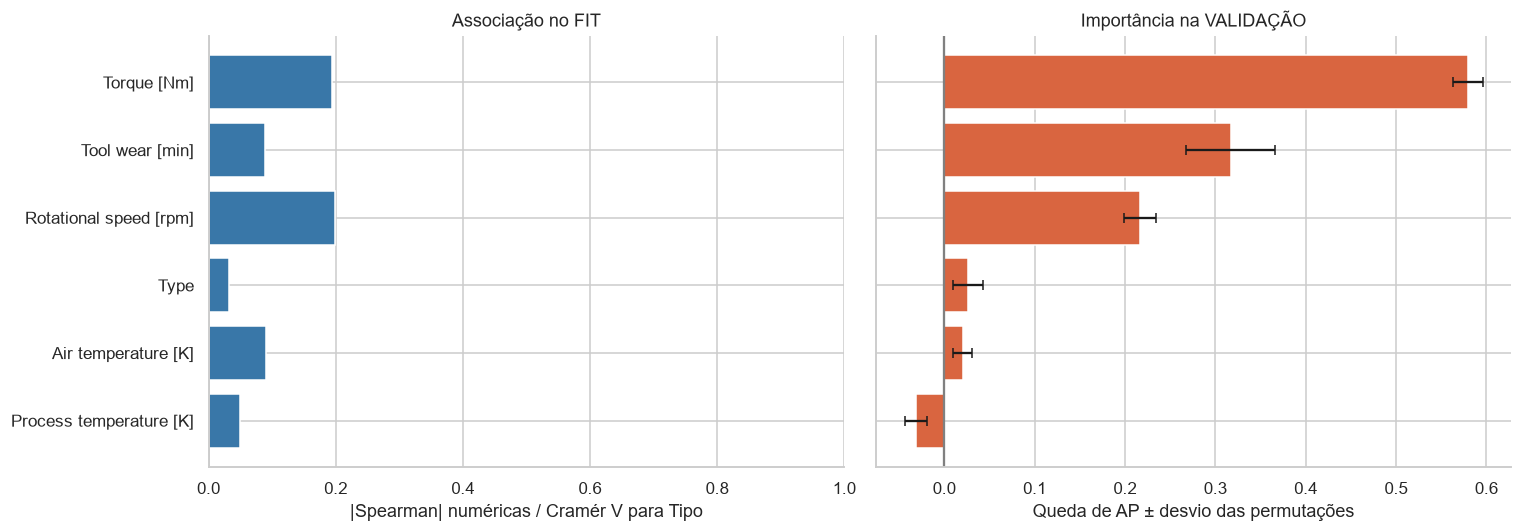

In [8]:
display(readable_table(report.table('feature_association_importance')))
report.feature_figure()

## 9. Diagnóstico por tamanho do prefixo

Parâmetros congelados da busca, prefixos ordenados e a mesma validação. Prefixos
de tamanhos distintos abrangem regimes diferentes: **não é uma learning curve i.i.d.
controlada**. É diagnóstico descritivo; não escolhe novamente os parâmetros.

,Observações de treino,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,1.600,Treino (prefixo),1.600,45,"2,81%","0,5000",1.553,2,0,45,"97,83%","100,00%","95,74%","99,87%","100,00%","0,13%","0,00%","2,94%","99,88%","99,94%",1,1,"0,0017","0,0135","0,9779","0,9776"
1,1.600,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.537,28,12,23,"53,49%","65,71%","45,10%","98,21%","99,23%","1,79%","34,29%","3,19%","97,50%","81,96%","0,5236","0,9434","0,0199","0,0744","0,5323","0,5225"
2,3.200,Treino (prefixo),3.200,77,"2,41%","0,5000",3.112,11,0,77,"93,33%","100,00%","87,50%","99,65%","100,00%","0,35%","0,00%","2,75%","99,66%","99,82%","0,9896","0,9998","0,0042","0,0234","0,9338","0,9316"
3,3.200,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.552,13,10,25,"68,49%","71,43%","65,79%","99,17%","99,36%","0,83%","28,57%","2,38%","98,56%","85,30%","0,7184","0,9526","0,0112","0,0508","0,6782","0,6776"
4,4.800,Treino (prefixo),4.800,221,"4,60%","0,5000",4.498,81,4,217,"83,62%","98,19%","72,82%","98,23%","99,91%","1,77%","1,81%","6,21%","98,23%","98,21%","0,9704","0,9984","0,0143","0,0580","0,8374","0,8271"
5,4.800,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.548,17,13,22,"59,46%","62,86%","56,41%","98,91%","99,17%","1,09%","37,14%","2,44%","98,12%","80,89%","0,6582","0,9694","0,0152","0,0590","0,5859","0,5850"
6,6.400,Treino (prefixo),6.400,265,"4,14%","0,5000",6.023,112,7,258,"81,26%","97,36%","69,73%","98,17%","99,88%","1,83%","2,64%","5,78%","98,14%","97,77%","0,9475","0,9973","0,0167","0,0662","0,8155","0,8031"
7,6.400,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.543,22,8,27,"64,29%","77,14%","55,10%","98,59%","99,48%","1,41%","22,86%","3,06%","98,12%","87,87%","0,6796","0,9671","0,0164","0,0628","0,6430","0,6335"


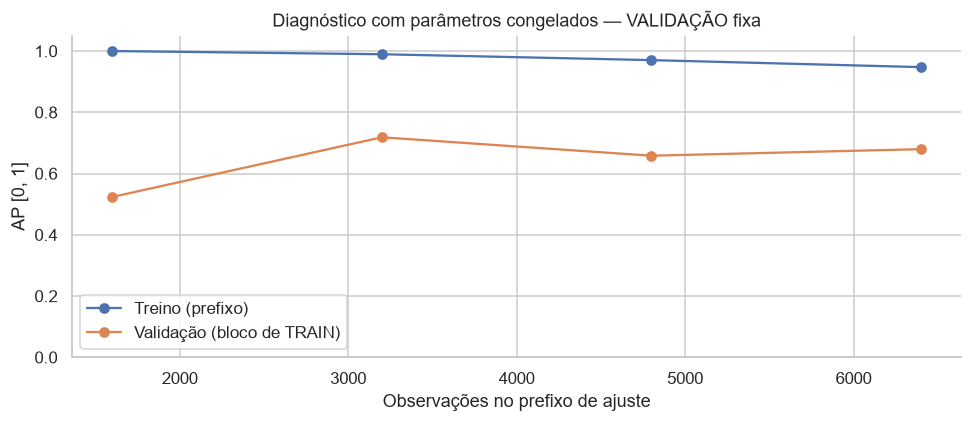

In [9]:
display(readable_table(report.table('learning_diagnostic')))
report.learning_figure()

## 10. Erros por segmento e ordem dos registros

Contagens, taxas reais, TP/FP/FN/TN e métricas por Type e faixas de sensores.
Limites das faixas aprendidos apenas em FIT; extremos cobrem valores futuros.
NaN indica denominador inexistente. Não somar suportes de features diferentes:
as mesmas observações aparecem em cada análise. UDI não representa tempo decorrido.

,Variável de agrupamento,Faixa / categoria,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Tipo,H,147,1,"0,68%","0,5000",145,1,0,1,"66,67%","100,00%","50,00%","99,32%","100,00%","0,68%","0,00%","1,36%","99,32%","99,66%","0,5000","0,9932","0,0120","0,0472","0,7047","0,6636"
1,Tipo,L,968,24,"2,48%","0,5000",929,15,6,18,"63,16%","75,00%","54,55%","98,41%","99,36%","1,59%","25,00%","3,41%","97,83%","86,71%","0,6971","0,9589","0,0175","0,0663","0,6291","0,6207"
2,Tipo,M,485,10,"2,06%","0,5000",469,6,2,8,"66,67%","80,00%","57,14%","98,74%","99,58%","1,26%","20,00%","2,89%","98,35%","89,37%","0,7955","0,9869","0,0155","0,0605","0,6683","0,6585"


,Variável de agrupamento,Faixa / categoria,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Temperatura do ar [K],"(298.1, 299.6]",33,0,"0,00%","0,5000",33,0,0,0,"0,00%",Não definido,Não definido,"100,00%","100,00%","0,00%",Não definido,"0,00%","100,00%",Não definido,Não definido,Não definido,"0,0060","0,0342",Não definido,Não definido
1,Temperatura do ar [K],"(299.6, 301.3]",1.359,30,"2,21%","0,5000",1.313,16,7,23,"66,67%","76,67%","58,97%","98,80%","99,47%","1,20%","23,33%","2,87%","98,31%","87,73%","0,6992","0,9661","0,0153","0,0588","0,6641","0,6581"
2,Temperatura do ar [K],"(301.3, 302.4]",208,5,"2,40%","0,5000",197,6,1,4,"53,33%","80,00%","40,00%","97,04%","99,49%","2,96%","20,00%","4,81%","96,63%","88,52%","0,5833","0,9764","0,0254","0,0934","0,5516","0,5179"
3,Temperatura do processo [K],"(309.4, 310.5]",521,9,"1,73%","0,5000",502,10,2,7,"53,85%","77,78%","41,18%","98,05%","99,60%","1,95%","22,22%","3,26%","97,70%","87,91%","0,7378","0,8854","0,0218","0,0857","0,5561","0,5278"
4,Temperatura do processo [K],"(310.5, 311.3]",544,12,"2,21%","0,5000",523,9,2,10,"64,52%","83,33%","52,63%","98,31%","99,62%","1,69%","16,67%","3,49%","97,98%","90,82%","0,7792","0,9901","0,0152","0,0578","0,6531","0,6353"
5,Temperatura do processo [K],"(311.3, inf]",535,14,"2,62%","0,5000",518,3,4,10,"74,07%","71,43%","76,92%","99,42%","99,23%","0,58%","28,57%","2,43%","98,69%","85,43%","0,7697","0,9901","0,0123","0,0456","0,7346","0,7340"
6,Velocidade de rotação [rpm],"(-inf, 1406.0]",334,21,"6,29%","0,5000",297,16,1,20,"70,18%","95,24%","55,56%","94,89%","99,66%","5,11%","4,76%","10,78%","94,91%","95,06%","0,7621","0,9782","0,0436","0,1525","0,7055","0,6760"
7,Velocidade de rotação [rpm],"(1406.0, 1469.0]",293,4,"1,37%","0,5000",285,4,2,2,"40,00%","50,00%","33,33%","98,62%","99,30%","1,38%","50,00%","2,05%","97,95%","74,31%","0,4640","0,9792","0,0138","0,0561","0,3983","0,3900"
8,Velocidade de rotação [rpm],"(1469.0, 1542.0]",364,1,"0,27%","0,5000",363,0,1,0,"0,00%","0,00%",Não definido,"100,00%","99,73%","0,00%","100,00%","0,00%","99,73%","50,00%","0,1429","0,9835","0,0042","0,0206",0,0
9,Velocidade de rotação [rpm],"(1542.0, 1643.0]",281,0,"0,00%","0,5000",281,0,0,0,"0,00%",Não definido,Não definido,"100,00%","100,00%","0,00%",Não definido,"0,00%","100,00%",Não definido,Não definido,Não definido,"0,0023","0,0164",Não definido,Não definido


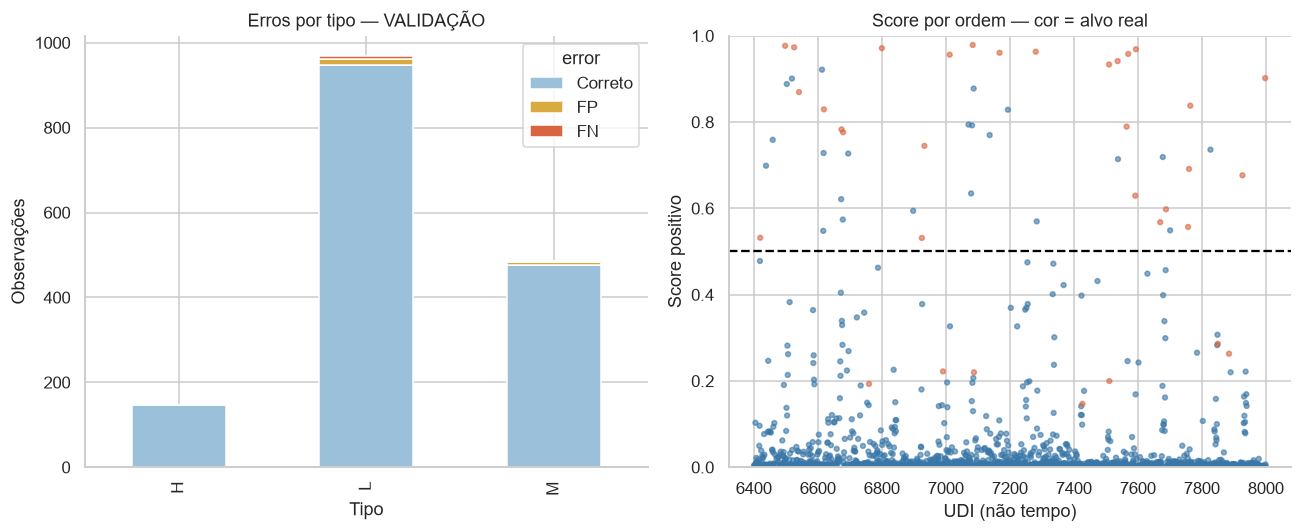

In [10]:
display(readable_table(report.table('segment_type')))
display(readable_table(report.table('segment_numeric')))
report.error_figure()

## 11. Artefato, reprodutibilidade e limites

O pipeline local corresponde ao refit em FIT (6.400), não a um modelo reajustado
nas 8.000 observações ou selecionado como vencedor do projeto. Não existe avaliação TEST.
O binário é local e ignorado no Git; carregar somente artefatos de origem confiável.

In [11]:
print('Pipeline:', manifest['model_path'])
print('SHA256:', manifest['model_sha256'])
print('Equivalência após serialização:', manifest['serialization_verified'])
print('Política de limiar:', manifest['threshold_policy'])
print('Figuras:', report.figures.relative_to(ROOT))
print('Tabelas:', report.tables.relative_to(ROOT))
display(manifest['limitations'])
display(translated_markdown('**Próxima decisão:** comparar os dois candidatos sob este mesmo protocolo, '
    'considerando AP, falhas perdidas, falsos alarmes, estabilidade e custo. '
    'Não ajustar features ou threshold com TEST. Nenhum vencedor de produção foi declarado.'))

Pipeline: models/train_xgboost_20261031T004336Z_06512d36/pipeline.joblib
SHA256: 85cfbd3b0b7d0373f3770d009c9d0d6a44b8435a562425f6ab5b90daa1533f40
Equivalência após serialização: True
Política de limiar: fixed reference; not tuned
Figuras: reports\figures\train_xgboost_20261031T004336Z_06512d36
Tabelas: reports\metrics\train_xgboost_20261031T004336Z_06512d36


['UDI is record order, not verified time',
 'no gap or physical machine ID',
 'CV winner scores are selection-optimistic',
 'validation belongs to EDA-explored TRAIN',
 'probability calibration not demonstrated',
 'no final TEST evaluation']

**Próxima decisão:** comparar os dois candidatos sob este mesmo protocolo, considerando AP, falhas perdidas, falsos alarmes, estabilidade e custo. Não ajustar features ou limiar com TEST. Nenhum vencedor de produção foi declarado.